In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from tqdm import tqdm

#changes default of autoreloader to continually reload (2) rather than only on restart
%load_ext autoreload
%autoreload 2

import os
import glob


desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
mypath = desktop
import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc

import data

In [2]:
from pathlib import Path
path_to_data='//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/'

STEDdata = {}
for file in glob.glob(path_to_data+"*Local*"):
    print(file)
    name = Path(file).name
    dendrite = 'dendrite'+name.split(' - ')[0]
    
    STEDdata[dendrite] = {'path':path_to_data} 
    STEDdata[dendrite]['file']= name
    STEDdata[dendrite]['ex_factor'] = 1
    STEDdata[dendrite]['res'] = 0.04



//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\14 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\20 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\25-1 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\26 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\26-1 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\41-2 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\42-2 - Local Diameter.csv


analyse frames in data dic

In [3]:
frames = [STEDdata]
for data in frames:
    for name, path in tqdm(data.items()): 
        print(data[name]['path'])
        file_path = data[name]['path']+data[name]['file']
        data[name] = branch_dsc(file_path, data[name]['res'], data[name]['ex_factor'])


  0%|          | 0/7 [00:00<?, ?it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


 14%|█▍        | 1/7 [00:00<00:01,  3.64it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


 29%|██▊       | 2/7 [00:00<00:02,  2.48it/s]

...

 57%|█████▋    | 4/7 [00:01<00:01,  2.98it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


 86%|████████▌ | 6/7 [00:01<00:00,  4.19it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


100%|██████████| 7/7 [00:01<00:00,  3.62it/s]


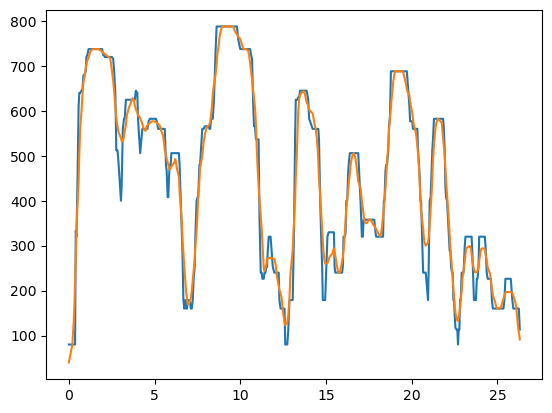

In [13]:
Dict=STEDdata['dendrite14']
df=Dict['data']
fig, ax1 = plt.subplots()
ax1.plot(df.length*Dict['res']/Dict['ex_factor'], df.diam/Dict['ex_factor']) 
ax1.plot(df.length*Dict['res']/Dict['ex_factor'], df.smth/Dict['ex_factor']) 
        
        # ax1.plot(dic['left_bases'], df.diam[dic['left_bases']], "o", color="red")
        # ax1.plot(df.length[dic['left_bases']], df.diam[dic['left_bases']], "o", color="red")
        # ax1.plot(df.length*Dict['res']/Dict['ex_factor'], df.diam[peaks]/Dict['ex_factor'], "x") #ax1.plot(df.length, df.diam[peaks], "x")
#ax1.plot(df.length[peaks]*Dict['res']/Dict['ex_factor'], df.diam[peaks]/Dict['ex_factor'], "x")
        # plt.xlim(270,285)
        # plt.ylim(200,1250)

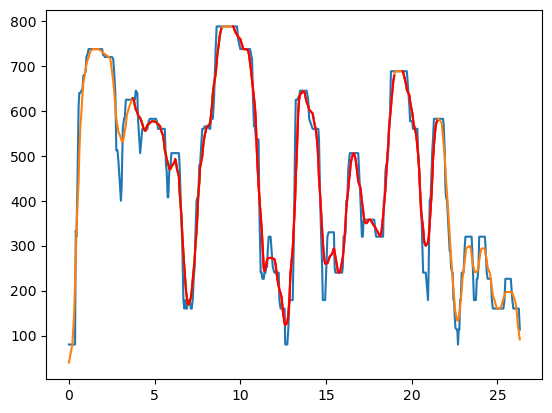

In [17]:
for dsc in Dict['DSCs']:
    #print(dsc)
    ax1.plot(dsc.length, dsc.smth, color='red') 

fig